In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')

# Remove exact duplicate records
df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Dataset shape: (3577, 8)


In [ ]:
# Features selected for clustering
clustering_features = [
    'year',
    'km_driven',
    'selling_price'
]

cluster_df = df[clustering_features].copy()

print("Clustering features:")
print(clustering_features)

print("\nShape:", cluster_df.shape)
print("\nFirst 5 rows:")
print(cluster_df.head())

Clustering features:
['year', 'km_driven', 'selling_price']

Shape: (3577, 3)

First 5 rows:
   year  km_driven  selling_price
0  2007      70000          60000
1  2007      50000         135000
2  2012     100000         600000
3  2017      46000         250000
4  2014     141000         450000


In [ ]:
# Standardize the clustering features
scaler = StandardScaler()

cluster_scaled = scaler.fit_transform(cluster_df)

# Convert back to DataFrame for easy inspection
cluster_scaled_df = pd.DataFrame(
    cluster_scaled,
    columns=clustering_features
)

print("Scaled data:")
print(cluster_scaled_df.head())

Scaled data:
       year  km_driven  selling_price
0 -1.402566   0.015754      -0.812819
1 -1.402566  -0.404650      -0.665538
2 -0.226418   0.646360       0.247604
3  0.949731  -0.488731      -0.439708
4  0.244042   1.508188      -0.046958


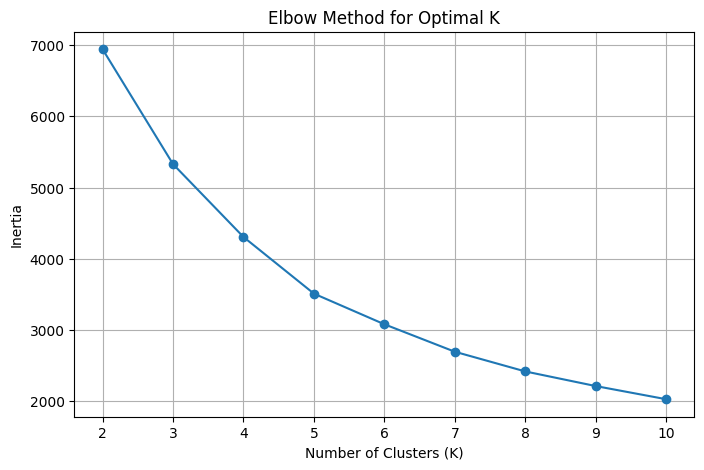

In [ ]:
# Calculate inertia for different values of K
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(cluster_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

K = 2: Silhouette Score = 0.3670
K = 3: Silhouette Score = 0.3847
K = 4: Silhouette Score = 0.3711
K = 5: Silhouette Score = 0.3333
K = 6: Silhouette Score = 0.3051
K = 7: Silhouette Score = 0.3151
K = 8: Silhouette Score = 0.3093
K = 9: Silhouette Score = 0.2944
K = 10: Silhouette Score = 0.2919


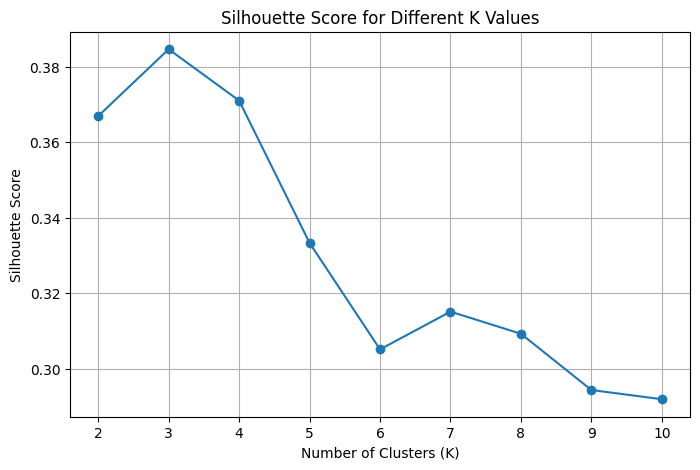

In [ ]:
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(cluster_scaled)

    score = silhouette_score(cluster_scaled, cluster_labels)
    silhouette_scores.append(score)

# Display scores
for k, score in zip(K_range, silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

used both the Elbow Method and Silhouette Score to determine the optimal number of clusters. The Elbow Method showed that the improvement in inertia started diminishing around K=4–5, while the Silhouette Score was highest at K=3 with a score of approximately 0.385. Therefore, selected K=3 for the final K-Means model.

In [ ]:
# Apply K-Means with the selected number of clusters
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(cluster_scaled)

# Add cluster labels to the original clustering dataframe
cluster_df['cluster'] = cluster_labels

print("Cluster counts:")
print(cluster_df['cluster'].value_counts().sort_index())

Cluster counts:
cluster
0    1610
1    1874
2      93
Name: count, dtype: int64


In [ ]:
# Calculate average characteristics of each cluster
cluster_summary = cluster_df.groupby('cluster')[clustering_features].mean()

print("Cluster Summary:")
print(cluster_summary)

Cluster Summary:
                year     km_driven  selling_price
cluster                                          
0        2009.424224  99531.131056   2.509295e+05
1        2015.843650  44193.826574   5.533029e+05
2        2016.161290  49944.623656   2.734398e+06


K-Means clustering divided the used-car dataset into three distinct market segments. Cluster 0 represents older and high-mileage vehicles with relatively low selling prices. Cluster 1 represents newer, lower-mileage vehicles in the mid-price range. Cluster 2 contains a small group of newer, relatively low-mileage and significantly higher-priced vehicles, representing the premium segment.

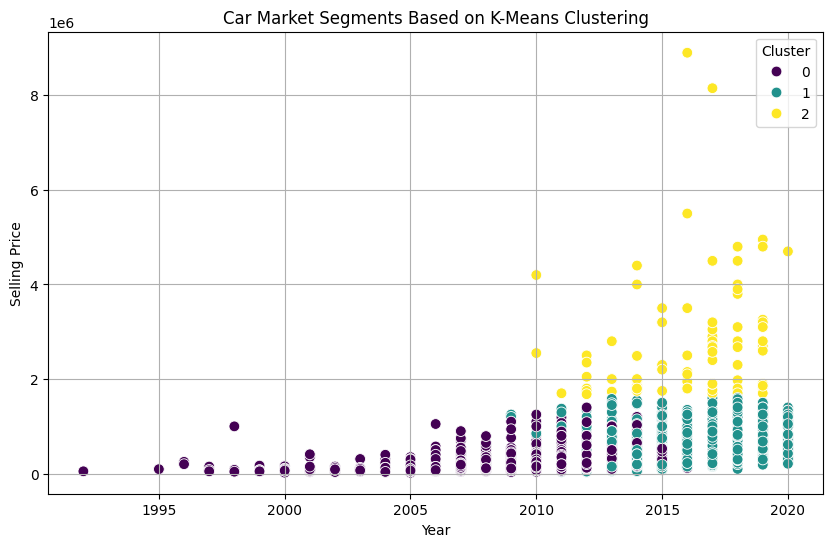

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_df,
    x='year',
    y='selling_price',
    hue='cluster',
    palette='viridis',
    s=60
)

plt.title('Car Market Segments Based on K-Means Clustering')
plt.xlabel('Year')
plt.ylabel('Selling Price')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

In [ ]:
# Add cluster size and percentage
cluster_summary = cluster_df.groupby('cluster')[clustering_features].mean()

cluster_summary['car_count'] = cluster_df['cluster'].value_counts().sort_index()
cluster_summary['percentage'] = (
    cluster_summary['car_count'] / len(cluster_df) * 100
)

print(cluster_summary.round(2))

            year  km_driven  selling_price  car_count  percentage
cluster                                                          
0        2009.42   99531.13      250929.47       1610       45.01
1        2015.84   44193.83      553302.94       1874       52.39
2        2016.16   49944.62     2734397.84         93        2.60


In [ ]:
cluster_names = {
    0: 'Older Budget Cars',
    1: 'Newer Mid-Range Cars',
    2: 'Premium Cars'
}

cluster_df['segment'] = cluster_df['cluster'].map(cluster_names)

print(cluster_df[['cluster', 'segment']].drop_duplicates().sort_values('cluster'))

    cluster               segment
0         0     Older Budget Cars
3         1  Newer Mid-Range Cars
12        2          Premium Cars


In [ ]:
final_summary = cluster_df.groupby('segment').agg(
    average_year=('year', 'mean'),
    average_km_driven=('km_driven', 'mean'),
    average_selling_price=('selling_price', 'mean'),
    car_count=('segment', 'count')
)

final_summary['percentage'] = (
    final_summary['car_count'] / len(cluster_df) * 100
)

print(final_summary.round(2))

                      average_year  average_km_driven  average_selling_price  \
segment                                                                        
Newer Mid-Range Cars       2015.84           44193.83              553302.94   
Older Budget Cars          2009.42           99531.13              250929.47   
Premium Cars               2016.16           49944.62             2734397.84   

                      car_count  percentage  
segment                                      
Newer Mid-Range Cars       1874       52.39  
Older Budget Cars          1610       45.01  
Premium Cars                 93        2.60  


In [ ]:
# Save clustering results
cluster_df.to_csv('/content/car_clustered_data.csv', index=False)

print("Clustering results saved successfully.")
print("File shape:", cluster_df.shape)

Clustering results saved successfully.
File shape: (3577, 5)
